**ANOMALY DETECTION OC-SVM**

In [2]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [31]:
job_names = ["net_v3_0per_k5", "net_v3_0per_k9", "net_v3_0per_k13", "net_v3_0per_k55"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_pca_{job_name}"          # una cartella per job: niente file vecchi mescolati
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_pca_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        # una riga per job
all_rules = {}      # tabella delle regole di ogni job

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "k": results["k"],
        "varianza_spiegata": results["varianza_spiegata"],
        "min_flood_area": results["min_flood_area"],
        "standardize": results["standardize"],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc": results["auroc"],
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])     # indice a due livelli: job, regola

df_summary

,k,varianza_spiegata,min_flood_area,standardize,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
job_name,,,,,,,,,,
net_v3_0per_k5,5,0.213983,0.0,True,2572,2402,2402,-201.2144 ± 44.8739,-233.8135 ± 42.7609,0.701663
net_v3_0per_k9,9,0.314863,0.0,True,2572,2402,2402,-177.1404 ± 40.1925,-207.2152 ± 40.2531,0.703005
net_v3_0per_k13,13,0.403110,0.0,True,2572,2402,2402,-155.0151 ± 35.0066,-181.2418 ± 35.6977,0.702671
net_v3_0per_k55,55,0.902910,0.0,True,2572,2402,2402,-26.8186 ± 9.9551,-33.1581 ± 12.1120,0.659215


In [32]:
df_rules

soglia      TP     FP  \
job_name        regola                                                   
net_v3_0per_k5  pca score < soglia (FA 5%)  -273.814789   425.0   85.0   
                pca score < soglia (FA 10%) -257.863159   710.0  148.0   
                pca score < soglia (FA 15%) -245.827591   966.0  212.0   
                pca score < soglia (FA 20%) -237.610672  1133.0  266.0   
                pca score < soglia (FA 25%) -231.883255  1271.0  310.0   
                pca score < soglia (FA 30%) -224.124710  1435.0  380.0   
net_v3_0per_k9  pca score < soglia (FA 5%)  -242.643402   454.0   72.0   
                pca score < soglia (FA 10%) -228.746674   715.0  146.0   
                pca score < soglia (FA 15%) -219.643829   910.0  190.0   
                pca score < soglia (FA 20%) -211.264069  1108.0  249.0   
                pca score < soglia (FA 25%) -203.317673  1302.0  317.0   
                pca score < soglia (FA 30%) -196.502960  1462.0  383.0   
net_v3_0per_k13 pca score < soglia (FA 5%)  -215.509705   412.0   62.0   
                pca score < soglia (FA 10%) -199.527283   731.0  135.0   
                pca score < soglia (FA 15%) -190.572174   946.0  189.0   
                pca score < soglia (FA 20%) -184.033508  1122.0  245.0   
                pca score < soglia (FA 25%) -177.749817  1293.0  313.0   
                pca score < soglia (FA 30%) -172.200577  1426.0  365.0   
net_v3_0per_k55 pca score < soglia (FA 5%)   -45.282417   361.0   58.0   
                pca score < soglia (FA 10%)  -40.394550   578.0  118.0   
                pca score < soglia (FA 15%)  -37.088875   763.0  189.0   
                pca score < soglia (FA 20%)  -34.842964   926.0  250.0   
                pca score < soglia (FA 25%)  -32.717110  1116.0  296.0   
                pca score < soglia (FA 30%)  -30.774637  1249.0  360.0   

                                                 FN      TN   FA_rate  \
job_name        regola                                                  
net_v3_0per_k5  pca score < soglia (FA 5%)   1977.0  1116.0  0.070774   
                pca score < soglia (FA 10%)  1692.0  1053.0  0.123231   
                pca score < soglia (FA 15%)  1436.0   989.0  0.176520   
                pca score < soglia (FA 20%)  1269.0   935.0  0.221482   
                pca score < soglia (FA 25%)  1131.0   891.0  0.258118   
                pca score < soglia (FA 30%)   967.0   821.0  0.316403   
net_v3_0per_k9  pca score < soglia (FA 5%)   1948.0  1129.0  0.059950   
                pca score < soglia (FA 10%)  1687.0  1055.0  0.121565   
                pca score < soglia (FA 15%)  1492.0  1011.0  0.158201   
                pca score < soglia (FA 20%)  1294.0   952.0  0.207327   
                pca score < soglia (FA 25%)  1100.0   884.0  0.263947   
                pca score < soglia (FA 30%)   940.0   818.0  0.318901   
net_v3_0per_k13 pca score < soglia (FA 5%)   1990.0  1139.0  0.051624   
                pca score < soglia (FA 10%)  1671.0  1066.0  0.112406   
                pca score < soglia (FA 15%)  1456.0  1012.0  0.157369   
                pca score < soglia (FA 20%)  1280.0   956.0  0.203997   
                pca score < soglia (FA 25%)  1109.0   888.0  0.260616   
                pca score < soglia (FA 30%)   976.0   836.0  0.303913   
net_v3_0per_k55 pca score < soglia (FA 5%)   2041.0  1143.0  0.048293   
                pca score < soglia (FA 10%)  1824.0  1083.0  0.098251   
                pca score < soglia (FA 15%)  1639.0  1012.0  0.157369   
                pca score < soglia (FA 20%)  1476.0   951.0  0.208160   
                pca score < soglia (FA 25%)  1286.0   905.0  0.246461   
                pca score < soglia (FA 30%)  1153.0   841.0  0.299750   

                                              MA_rate       REC      PREC  \
job_name        regola                                                      
net_v3_0per_k5  pca score < soglia (FA 5%)   0.823064  0.176936  0.8333

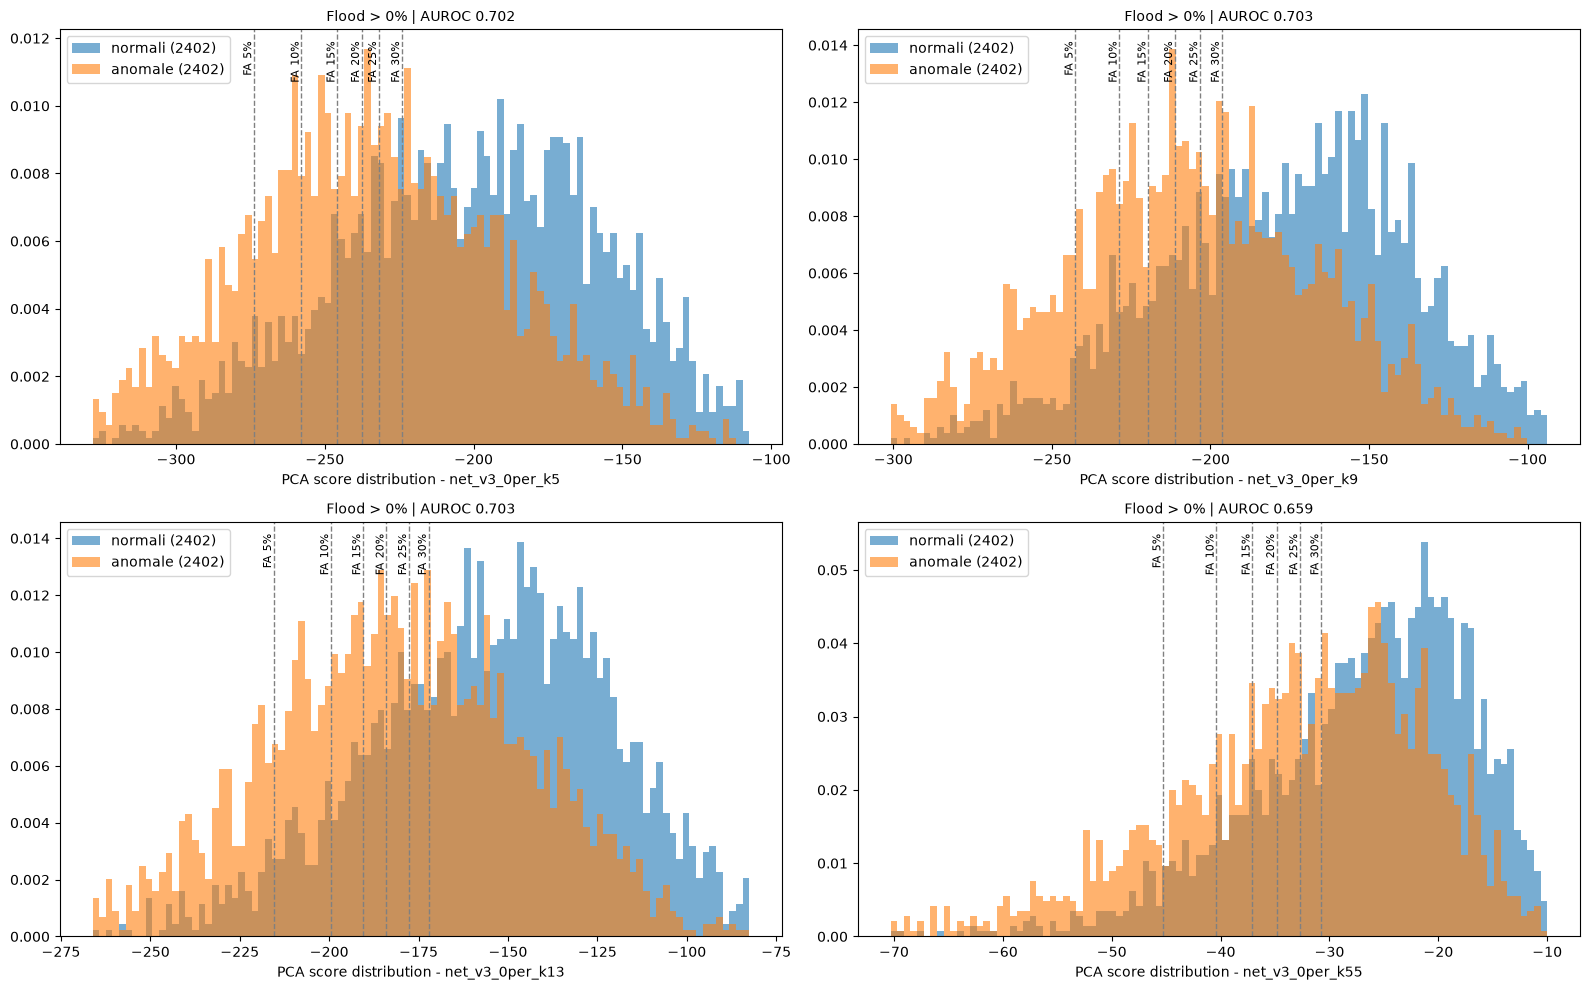

In [33]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])               # si taglia lo 0.5% piu' estremo per lato
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    for nome, r in results["rules"].items():                     # una riga tratteggiata per ogni soglia salvata nel json
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(f"PCA score distribution - {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           # spegne i riquadri vuoti se i job sono dispari
    ax.axis("off")

plt.tight_layout()
plt.show()

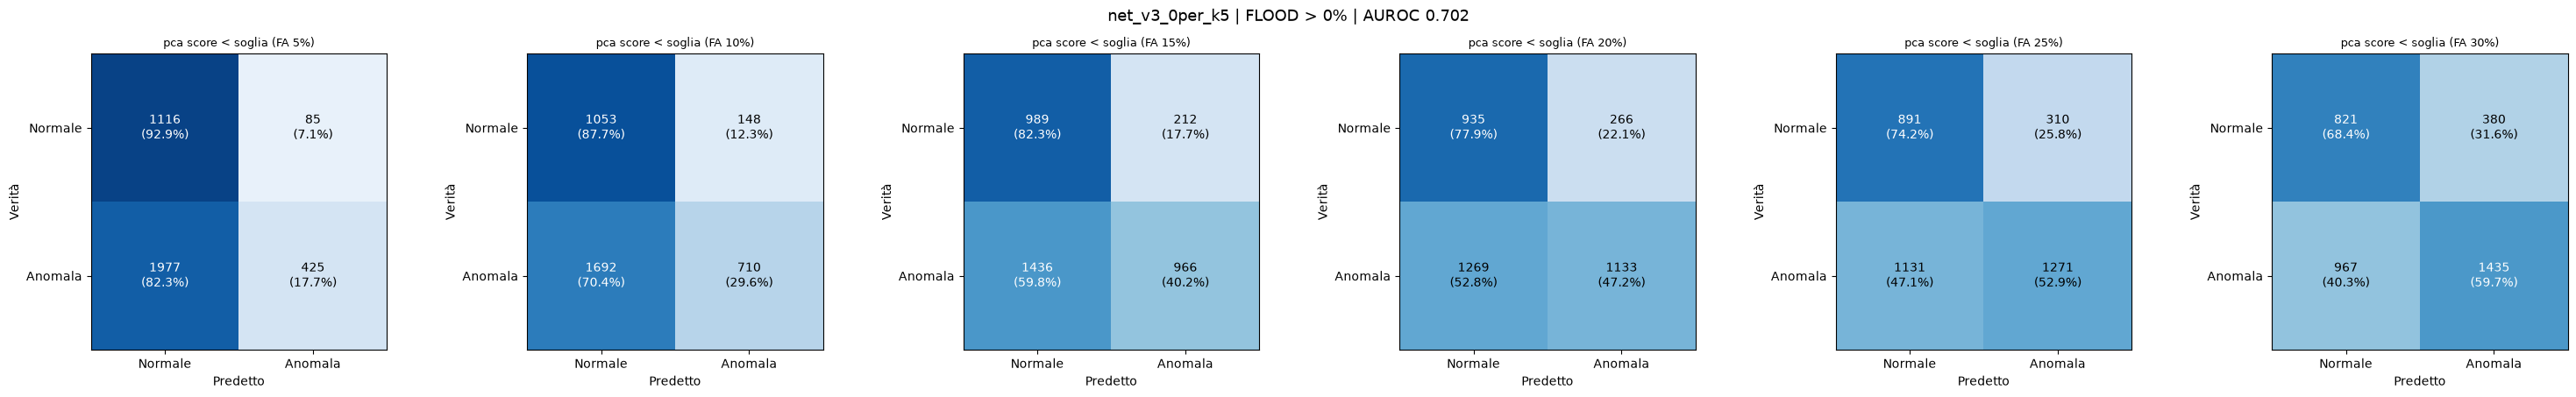

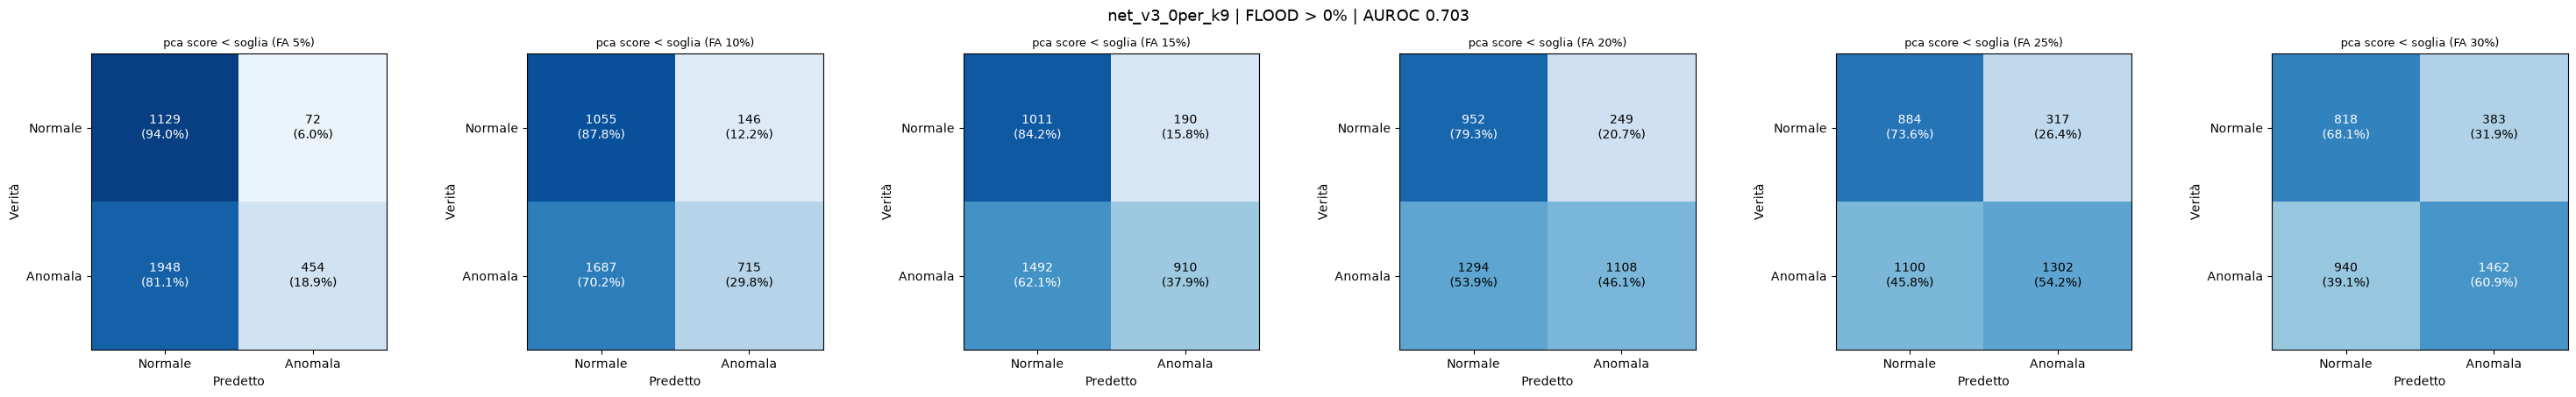

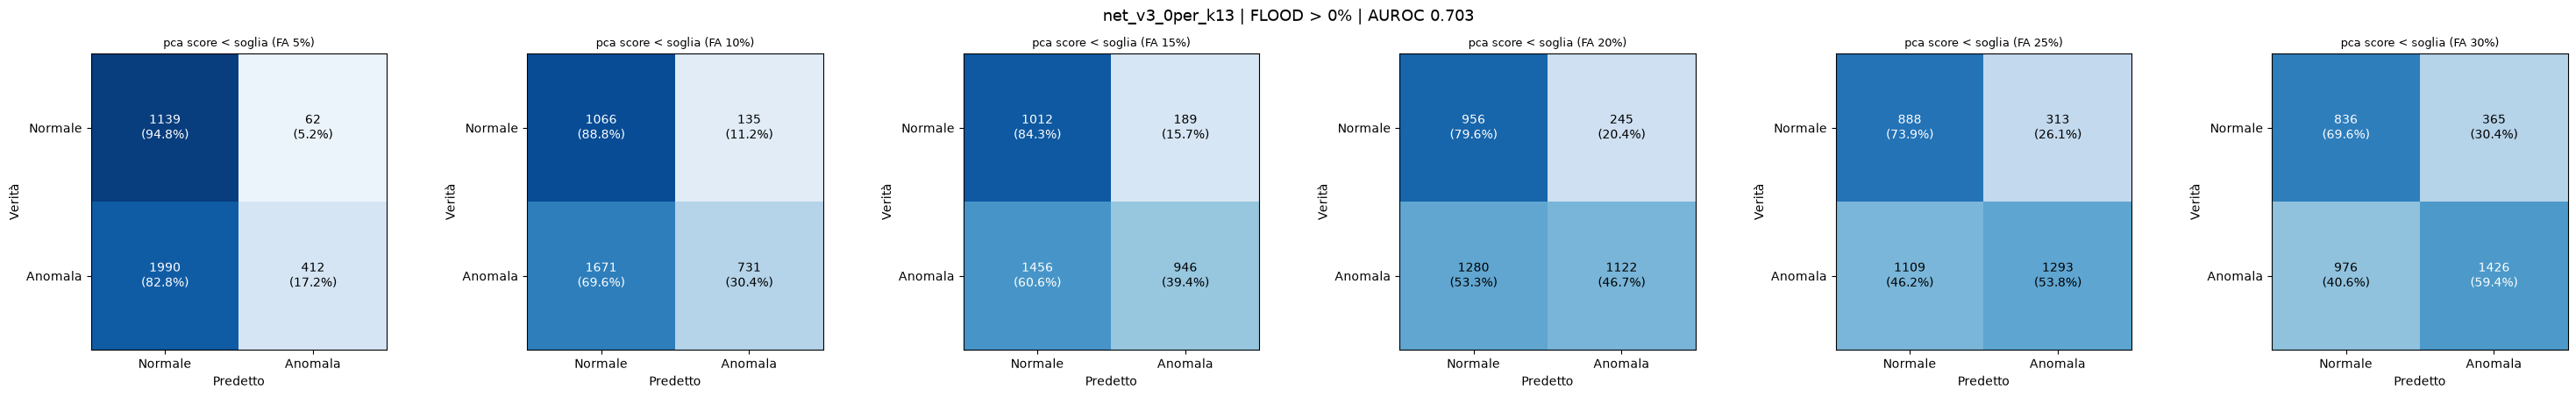

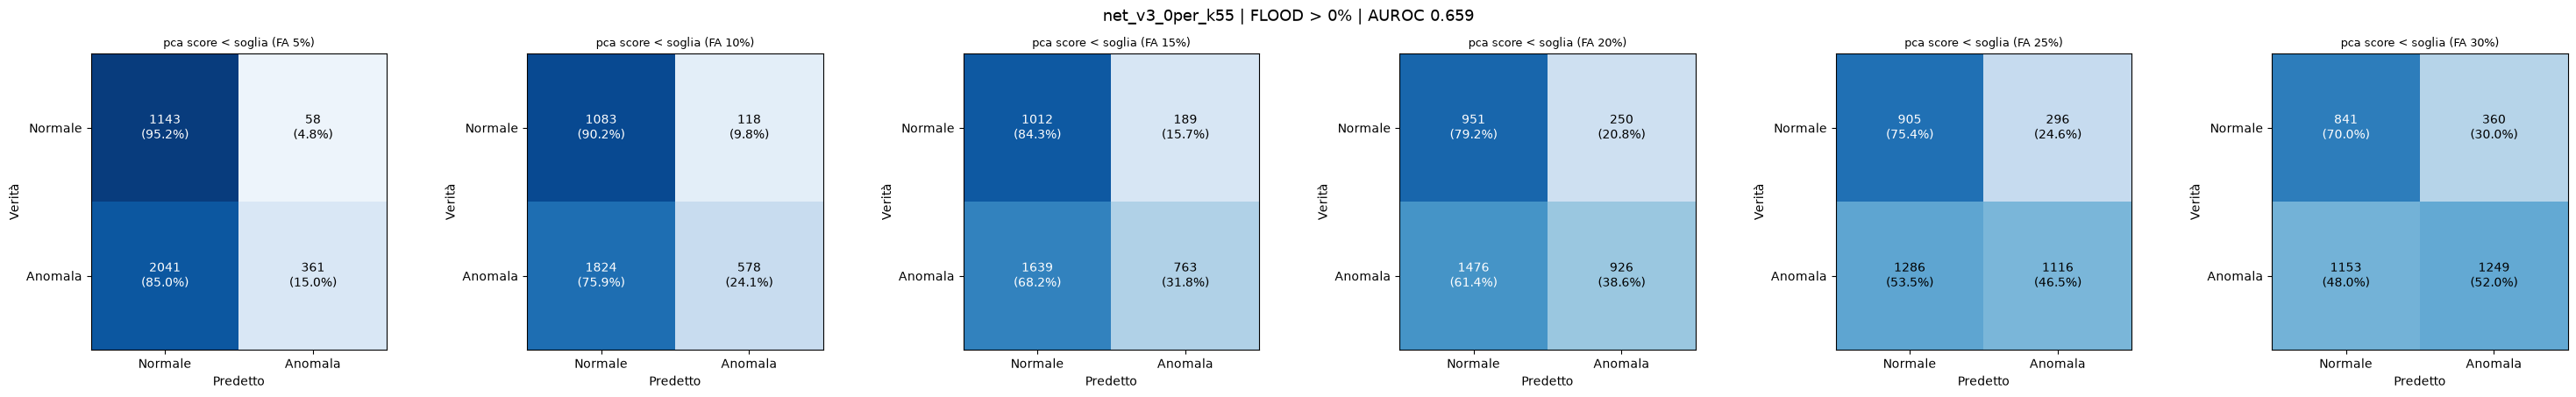

In [34]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"{job_name} | FLOOD > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)